In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare, binomtest, pearsonr, norm
from pathlib import Path


In [9]:
from pathlib import Path
import numpy as np
import pandas as pd

files = {
    "Linux /dev/urandom": "linux_urandom.bin",
    "OpenSSL rand": "openssl_rand.bin",
    ".NET RNG on Linux": "dotnet_rng.bin"
}

data = {}

for name, filename in files.items():
    path = Path(filename)

    if not path.exists():
        raise FileNotFoundError(filename)

    raw = path.read_bytes()

    if len(raw) < 1048576:
        raise ValueError(f"{filename} contains less than 1 MiB")

    data[name] = np.frombuffer(raw, dtype=np.uint8)

display(pd.DataFrame({
    "Mechanism": list(data.keys()),
    "File Size (bytes)": [len(values) for values in data.values()]
}))



,Mechanism,File Size (bytes)
0,Linux /dev/urandom,1048576
1,OpenSSL rand,1048576
2,.NET RNG on Linux,1048576


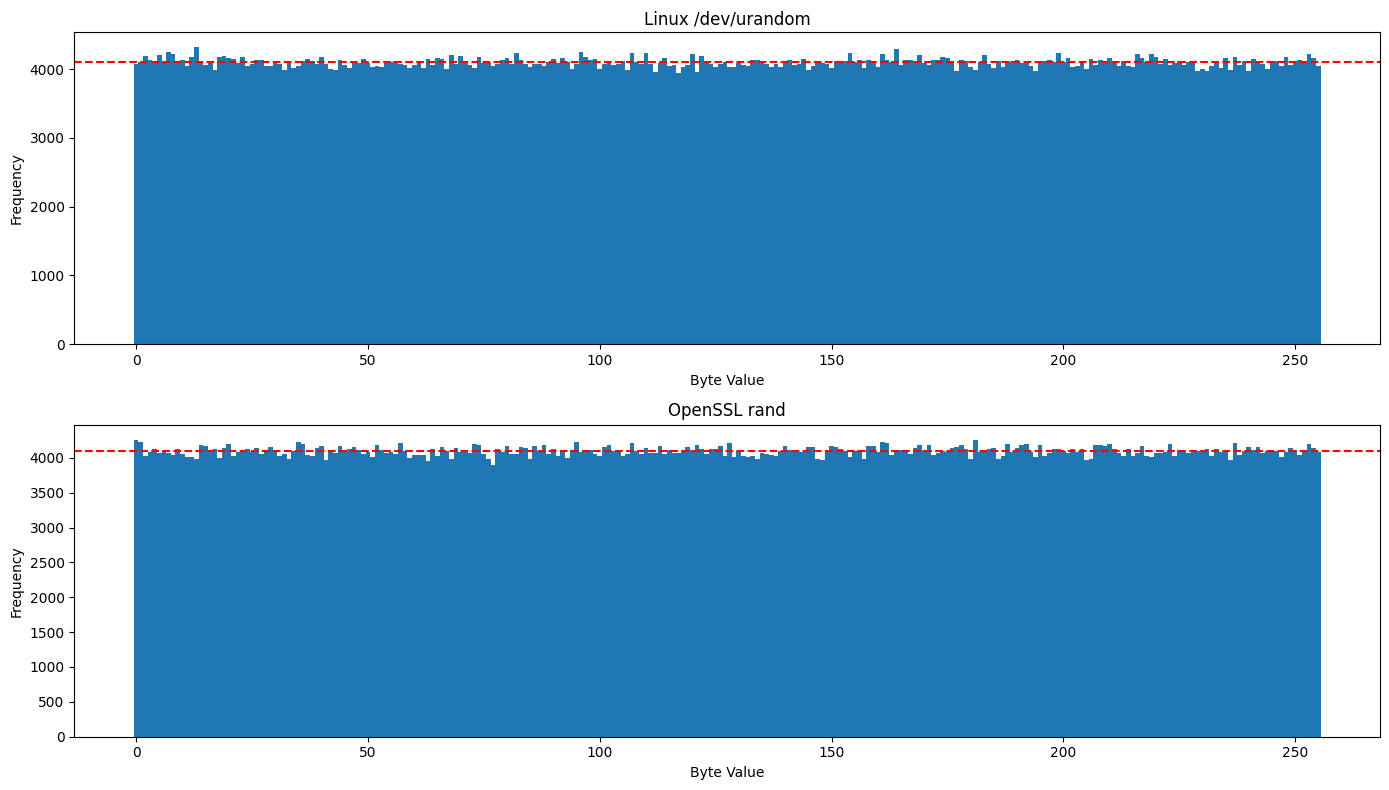

,Mechanism,Chi-square Statistic,P-value,Minimum Frequency,Maximum Frequency
0,Linux /dev/urandom,261.238281,0.380762,3950,4318
1,OpenSSL rand,256.442383,0.462848,3894,4260


In [14]:
byte_results = []

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

for ax, (name, values) in zip(axes, data.items()):
    counts = np.bincount(values, minlength=256)
    result = chisquare(counts)

    byte_results.append({
        "Mechanism": name,
        "Chi-square Statistic": result.statistic,
        "P-value": result.pvalue,
        "Minimum Frequency": counts.min(),
        "Maximum Frequency": counts.max()
    })

    ax.bar(np.arange(256), counts, width=1)
    ax.axhline(4096, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Byte Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

display(pd.DataFrame(byte_results))


In [11]:
bit_results = []

for name, values in data.items():
    bits = np.unpackbits(values)
    ones = int(bits.sum())
    zeros = len(bits) - ones
    result = binomtest(ones, len(bits), 0.5)

    bit_results.append({
        "Mechanism": name,
        "Total Bits": len(bits),
        "Ones": ones,
        "Zeros": zeros,
        "Percentage of Ones": 100 * ones / len(bits),
        "P-value": result.pvalue
    })

display(pd.DataFrame(bit_results))


,Mechanism,Total Bits,Ones,Zeros,Percentage of Ones,P-value
0,Linux /dev/urandom,8388608,4192695,4195913,49.980819,0.266687
1,OpenSSL rand,8388608,4194217,4194391,49.998963,0.952370
2,.NET RNG on Linux,8388608,4193190,4195418,49.986720,0.441947


In [12]:
pattern_results = []

for name, values in data.items():
    adjacent_equal = int(np.count_nonzero(values[1:] == values[:-1]))

    blocks = values[:len(values) // 4 * 4].reshape(-1, 4)
    unique_blocks = len(np.unique(blocks, axis=0))

    bits = np.unpackbits(values)
    changes = np.flatnonzero(bits[1:] != bits[:-1]) + 1
    boundaries = np.concatenate(([0], changes, [len(bits)]))
    longest_run = int(np.diff(boundaries).max())

    pattern_results.append({
        "Mechanism": name,
        "Adjacent Identical Bytes": adjacent_equal,
        "Total Four-Byte Blocks": len(blocks),
        "Unique Four-Byte Blocks": unique_blocks,
        "Duplicate Four-Byte Blocks": len(blocks) - unique_blocks,
        "Longest Identical-Bit Run": longest_run
    })

display(pd.DataFrame(pattern_results))


,Mechanism,Adjacent Identical Bytes,Total Four-Byte Blocks,Unique Four-Byte Blocks,Duplicate Four-Byte Blocks,Longest Identical-Bit Run
0,Linux /dev/urandom,4221,262144,262137,7,27
1,OpenSSL rand,4059,262144,262139,5,25
2,.NET RNG on Linux,4119,262144,262135,9,22


In [7]:
correlation_results = []

for name, values in data.items():
    x = values[:-1].astype(np.float64)
    y = values[1:].astype(np.float64)

    result = pearsonr(x, y)

    correlation_results.append({
        "Mechanism": name,
        "Pearson Correlation": result.statistic,
        "P-value": result.pvalue
    })

display(pd.DataFrame(correlation_results))


,Mechanism,Pearson Correlation,P-value
0,Linux /dev/urandom,-0.000886,0.364408
1,OpenSSL rand,0.001947,0.046226


In [13]:
def runs_test(values):
    bits = np.unpackbits(values)
    n = len(bits)
    ones = int(bits.sum())
    zeros = n - ones

    if ones == 0 or zeros == 0:
        return 1, np.nan, np.nan, 0.0

    runs = 1 + int(np.count_nonzero(bits[1:] != bits[:-1]))
    expected = 1 + (2 * ones * zeros) / n
    variance = (2 * ones * zeros * (2 * ones * zeros - n)) / (n**2 * (n - 1))
    z = (runs - expected) / np.sqrt(variance)
    p_value = 2 * norm.sf(abs(z))

    return runs, expected, z, p_value

runs_results = []

for name, values in data.items():
    runs, expected, z, p_value = runs_test(values)

    runs_results.append({
        "Mechanism": name,
        "Observed Runs": runs,
        "Expected Runs": expected,
        "Z-score": z,
        "P-value": p_value
    })

display(pd.DataFrame(runs_results))


,Mechanism,Observed Runs,Expected Runs,Z-score,P-value
0,Linux /dev/urandom,4192747,4.194304e+06,-1.075426,0.282184
1,OpenSSL rand,4193218,4.194305e+06,-0.750609,0.452888
2,.NET RNG on Linux,4190974,4.194305e+06,-2.299965,0.021450
